# Step 2 – Exploring the relations in UR3 CobotOps

Goal: visualise the relations that matter for **grip-loss prediction** before building the benchmark.
Each cell answers one question. Vocabulary:
- **cycle**: one repetition of the pick-and-place task (≈ 25 s). Identified by a *change* of the `cycle` counter (the counter goes back from 232 to 224 once, so its values are not unique).
- **event / onset**: a grip loss spans several consecutive seconds (an *event*); its **onset** is its first second.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4)

## 1. Load and clean

In [2]:
# French CSV format: ';' separates columns, ',' is the decimal separator
df = pd.read_csv("UR3CobotOps.csv", sep=";", decimal=",")
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]        # empty trailing columns
df.columns = df.columns.str.strip()                           # 'cycle ' -> 'cycle'
df = df.rename(columns={"Temperature_T0": "Temperature_J0"})  # T0 is joint J0

df["ts"] = pd.to_datetime(df["Timestamp"].str.strip('"'), utc=True)  # 863 quoted timestamps
df["GL"] = df["grip_lost"].eq("VRAI").astype(int)
df["PS"] = df["Robot_ProtectiveStop"].map({"VRAI": 1, "FAUX": 0})    # NaN on the 54 empty rows
df["nan_row"] = df["Current_J1"].isna()

CUR = [f"Current_J{i}" for i in range(6)]
TEM = [f"Temperature_J{i}" for i in range(6)]
SPD = [f"Speed_J{i}" for i in range(6)]
SENSORS = CUR + TEM + SPD + ["Tool_current"]
print(df.shape)
df[["ts", "cycle", "GL", "PS"] + SENSORS[:3]].head()

(7409, 28)


,ts,cycle,GL,PS,Current_J0,Current_J1,Current_J2
0,2022-10-26 08:17:21.847+00:00,1,0,0.0,0.109628,-2.024669,-1.531442
1,2022-10-26 08:17:22.852+00:00,1,0,0.0,0.595605,-2.278456,-0.866556
2,2022-10-26 08:17:23.857+00:00,1,0,0.0,-0.229474,-2.800408,-2.304336
3,2022-10-26 08:17:24.863+00:00,1,0,0.0,0.065053,-3.687768,-1.217652
4,2022-10-26 08:17:25.877+00:00,1,0,0.0,0.884140,-2.938830,-1.794076


In [3]:
# Structure of the time series
df["segment"]  = (df["ts"].diff().dt.total_seconds() > 5).cumsum()   # recording breaks
df["cycle_id"] = (df["cycle"] != df["cycle"].shift()).cumsum()       # unique cycle id
df["pos"]      = df.groupby("cycle_id").cumcount()                   # seconds since cycle start
df["onset"]    = (df["GL"] == 1) & (df["GL"].shift(fill_value=0) == 0)
df["event_id"] = df["onset"].cumsum().where(df["GL"] == 1)

print("segments (rows):", df.groupby("segment").size().tolist())
print("cycles:", df["cycle_id"].nunique(), "| grip-loss rows:", df["GL"].sum(),
      "| events:", df["onset"].sum())
d = df[~df["nan_row"]].copy()   # rows with sensor values, used for the statistics below

segments (rows): [1094, 72, 1703, 4540]
cycles: 249 | grip-loss rows: 243 | events: 77


## 2. Time: is the grip-loss rate stable during the day?
Temperatures rise while the robot warms up. If grip losses are more frequent at some moments, any variable that follows time (temperatures, cycle counter) will *look* predictive.

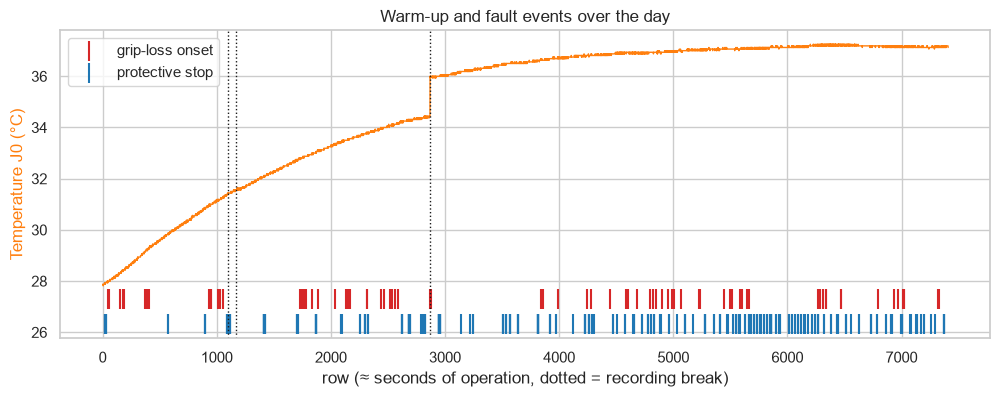

In [4]:
# x axis = row number (≈ seconds of operation), so the 5 h lunch gap is not drawn
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d.index, d["Temperature_J0"], color="tab:orange", lw=1)
ax.set_ylabel("Temperature J0 (°C)", color="tab:orange")
low = d["Temperature_J0"].min()
ons, ps = d[d["onset"]], d[d["PS"] == 1]
ax.scatter(ons.index, np.full(len(ons), low - 0.5), marker="|", s=200, color="tab:red", label="grip-loss onset")
ax.scatter(ps.index, np.full(len(ps), low - 1.5), marker="|", s=200, color="tab:blue", label="protective stop")
for b in df.index[df["segment"].diff() > 0]:
    ax.axvline(b, color="k", ls=":", lw=1)   # recording breaks
ax.set_xlabel("row (≈ seconds of operation, dotted = recording break)")
ax.legend(loc="upper left"); ax.set_title("Warm-up and fault events over the day")
plt.show()

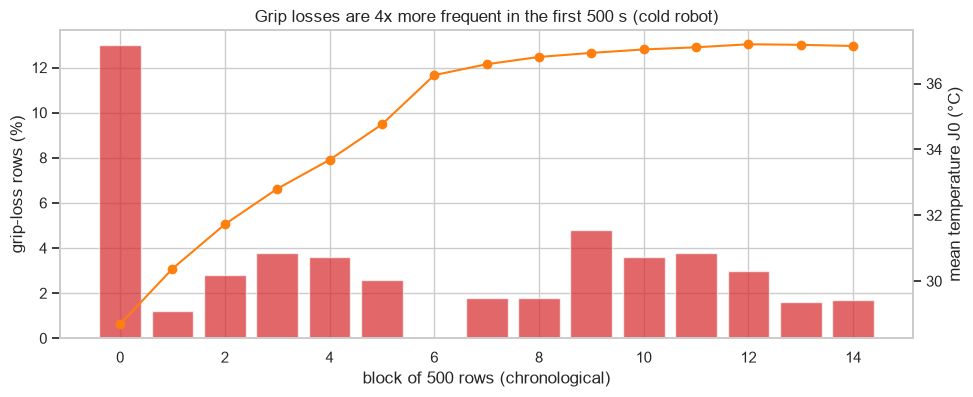

In [5]:
# Grip-loss rate and mean temperature per block of 500 seconds
blocks = d.groupby(np.arange(len(d)) // 500).agg(gl_rate=("GL", "mean"),
                                                   temp=("Temperature_J0", "mean"))
fig, ax = plt.subplots()
ax.bar(blocks.index, blocks["gl_rate"] * 100, color="tab:red", alpha=.7)
ax.set_xlabel("block of 500 rows (chronological)"); ax.set_ylabel("grip-loss rows (%)")
ax2 = ax.twinx(); ax2.plot(blocks.index, blocks["temp"], "o-", color="tab:orange")
ax2.set_ylabel("mean temperature J0 (°C)"); ax2.grid(False)
ax.set_title("Grip losses are 4x more frequent in the first 500 s (cold robot)")
plt.show()

**Reading:** the first block has ~13 % grip-loss rows against ~3 % afterwards. Temperature and time are confounded: a model could learn "cold ⇒ grip loss" from this start-up period only. A chronological split exposes this (the test period is warm).

## 3. Redundancy between sensors

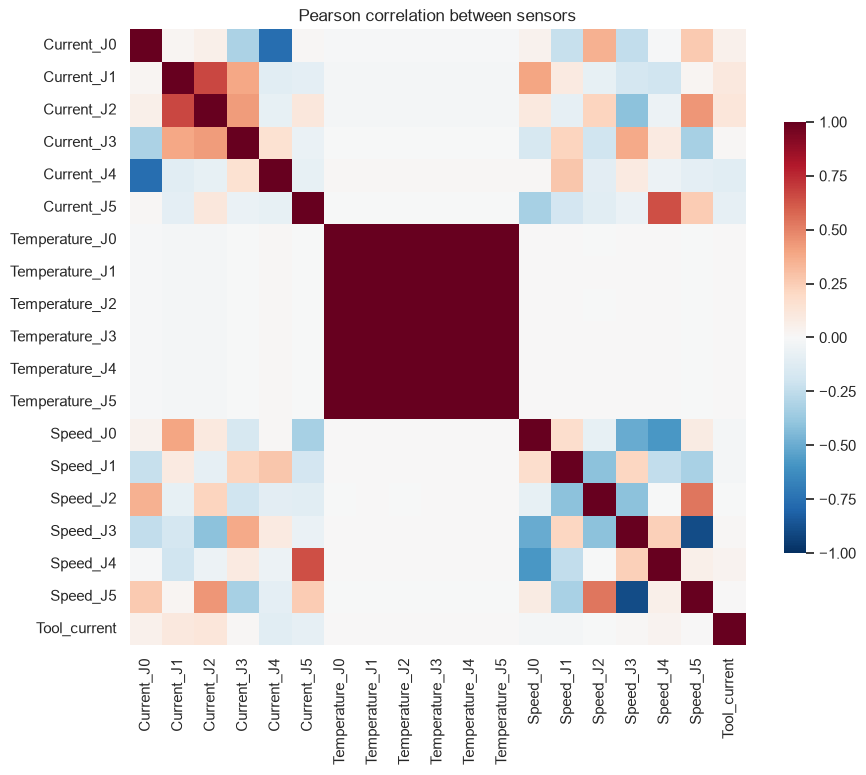

min correlation between the 6 temperatures: 0.993


In [6]:
corr = d[SENSORS].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": .7})
plt.title("Pearson correlation between sensors")
plt.show()
print("min correlation between the 6 temperatures:",
      round(corr.loc[TEM, TEM].values.min(), 3))

**Reading:** the 6 temperatures are almost identical (r ≈ 1): they carry one piece of information (how warm the robot is ≈ time of day). Keep one of them, or their mean, to avoid redundancy.

## 4. Which signals differ during a grip loss?
Univariate AUC = probability that a random grip-loss row has a higher value than a random normal row (0.5 = no difference; far from 0.5 in either direction = discriminant).

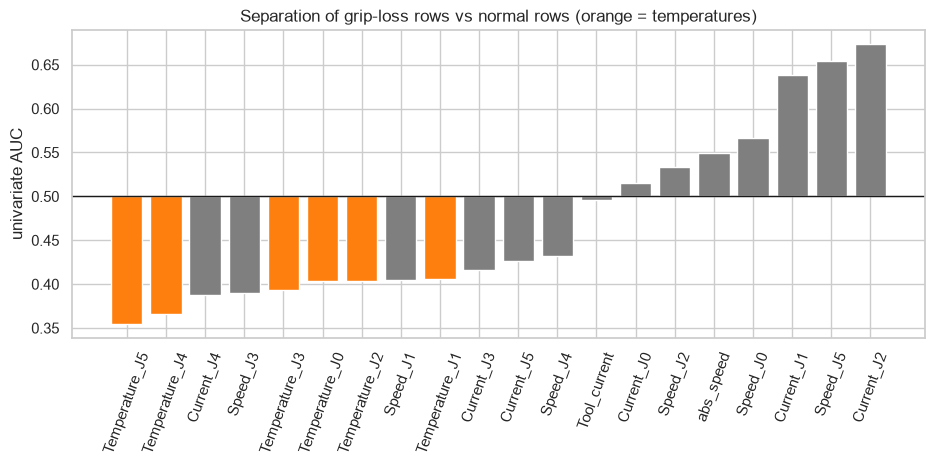

In [7]:
def auc(feature):
    a, b = d.loc[d["GL"] == 1, feature], d.loc[d["GL"] == 0, feature]
    return stats.mannwhitneyu(a, b).statistic / (len(a) * len(b))

d["abs_speed"] = d[SPD].abs().sum(axis=1)
aucs = pd.Series({f: auc(f) for f in SENSORS + ["abs_speed"]}).sort_values()
colors = ["tab:orange" if f in TEM else "tab:gray" for f in aucs.index]
plt.figure(figsize=(11, 4))
plt.bar(aucs.index, aucs - .5, bottom=.5, color=colors)
plt.axhline(.5, color="k", lw=1); plt.xticks(rotation=70); plt.ylabel("univariate AUC")
plt.title("Separation of grip-loss rows vs normal rows (orange = temperatures)")
plt.show()

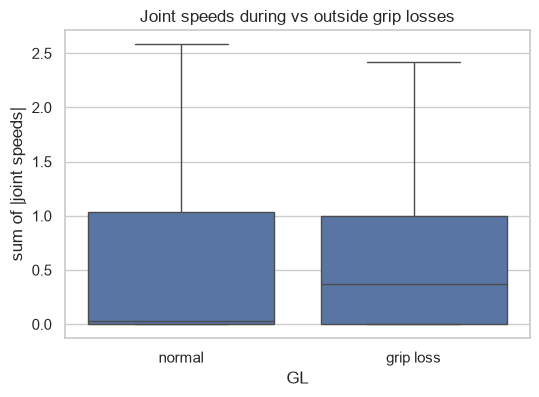

GL
0    0.031995
1    0.371005
Name: abs_speed, dtype: float64


In [8]:
# The robot keeps moving during a grip loss
plt.figure(figsize=(6, 4))
sns.boxplot(data=d, x="GL", y="abs_speed", showfliers=False)
plt.xticks([0, 1], ["normal", "grip loss"]); plt.ylabel("sum of |joint speeds|")
plt.title("Joint speeds during vs outside grip losses")
plt.show()
print(d.groupby("GL")["abs_speed"].median())

**Reading:** the strongest differences (speeds, currents J1/J2 that are less negative = less load) appear **during** the loss. They may be *consequences* (the arm no longer carries the part) rather than *causes*. This is the leakage risk: we must predict **before the onset** and drop the rows where a loss is already ongoing.

## 5. Position in the cycle

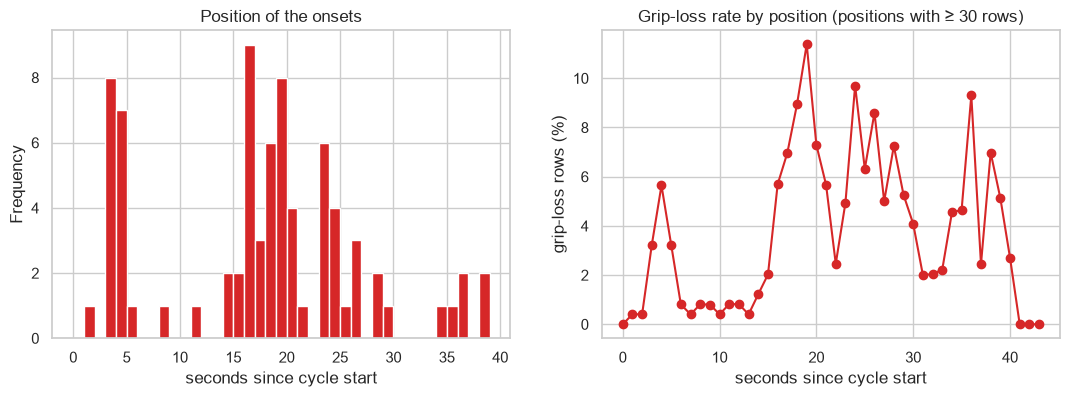

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
d.loc[d["onset"], "pos"].plot.hist(bins=range(0, 40), ax=axes[0], color="tab:red")
axes[0].set_xlabel("seconds since cycle start"); axes[0].set_title("Position of the onsets")

rate = d.groupby("pos")["GL"].agg(["mean", "size"]).query("size >= 30")
axes[1].plot(rate.index, rate["mean"] * 100, "o-", color="tab:red")
axes[1].set_xlabel("seconds since cycle start"); axes[1].set_ylabel("grip-loss rows (%)")
axes[1].set_title("Grip-loss rate by position (positions with ≥ 30 rows)")
plt.show()

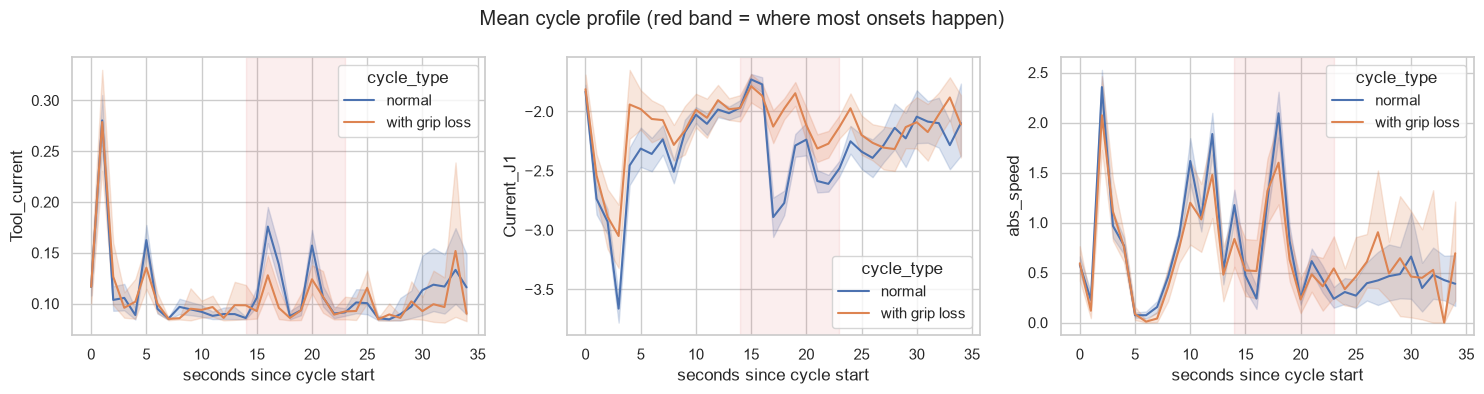

In [10]:
# Typical cycle profile: mean signal by position, cycles with vs without grip loss
gl_cycles = set(d.loc[d["GL"] == 1, "cycle_id"])
d["cycle_type"] = np.where(d["cycle_id"].isin(gl_cycles), "with grip loss", "normal")
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, col in zip(axes, ["Tool_current", "Current_J1", "abs_speed"]):
    sns.lineplot(data=d[d["pos"] < 35], x="pos", y=col, hue="cycle_type",
                 errorbar=("ci", 95), ax=ax)
    ax.axvspan(14, 23, color="tab:red", alpha=.08)
    ax.set_xlabel("seconds since cycle start")
fig.suptitle("Mean cycle profile (red band = where most onsets happen)")
plt.tight_layout(); plt.show()

**Reading:** grip losses are concentrated in a phase of the task (14–23 s). Position in the cycle alone is therefore a strong, "dumb" predictor: it is the baseline that the models must beat to show that they learn more than the task clock.

## 6. Are there precursors before the onset?
For each event we look at the signals from 10 s before to 5 s after the onset, minus the **normal** value at the same position in the cycle (to remove the cycle shape). A curve that moves away from 0 **before** 0 is a usable precursor; a move **after** 0 is a consequence.

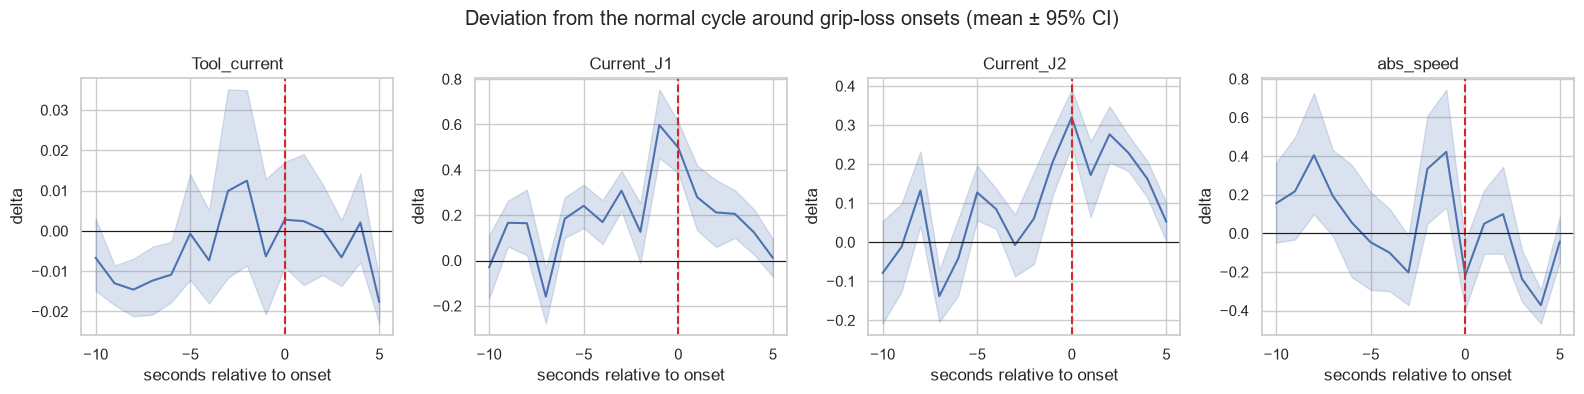

In [11]:
normal_profile = d[d["cycle_type"] == "normal"].groupby("pos")[SENSORS + ["abs_speed"]].mean()
df["abs_speed"] = df[SPD].abs().sum(axis=1)

def aligned(col, lags=range(-10, 6)):
    rows = []
    for i in np.where(df["onset"])[0]:
        for k in lags:
            j = i + k
            if 0 <= j < len(df) and df.at[j, "segment"] == df.at[i, "segment"]:
                ref = normal_profile[col].get(df.at[j, "pos"], np.nan)
                rows.append({"lag": k, "delta": df.at[j, col] - ref})
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)
for ax, col in zip(axes, ["Tool_current", "Current_J1", "Current_J2", "abs_speed"]):
    sns.lineplot(data=aligned(col), x="lag", y="delta", errorbar=("ci", 95), ax=ax)
    ax.axvline(0, color="tab:red", ls="--"); ax.axhline(0, color="k", lw=.8)
    ax.set_title(col); ax.set_xlabel("seconds relative to onset")
fig.suptitle("Deviation from the normal cycle around grip-loss onsets (mean ± 95% CI)")
plt.tight_layout(); plt.show()

**Reading:** `Current_J1` drifts above its normal value (less load) from about 6 s before the onset and peaks 1 s before it; `Current_J2` rises 1–2 s before. These are **usable precursors**, but short ones: they suggest a horizon *N* of a few seconds and window features over the last ~5 s. `Tool_current` shows nothing clear. In section 5, the J1 load dip at 16–17 s is missing in cycles with a grip loss: the part may already be badly held before the label switches to 1 (the label may lag the physical event).

## 7. Events: duration, spacing, events per cycle

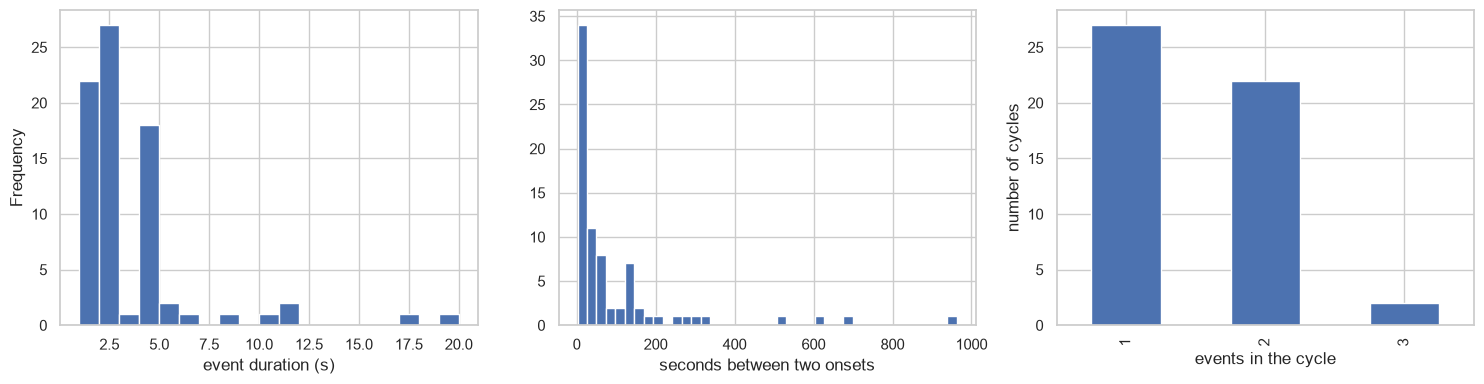

77 events, median duration 2 s, 6 pairs of onsets ≤ 10 s apart


In [12]:
ev = df[df["GL"] == 1].groupby("event_id").agg(duration=("GL", "size"), cycle_id=("cycle_id", "first"))
gaps = np.diff(np.where(df["onset"])[0])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ev["duration"].plot.hist(bins=range(1, 21), ax=axes[0]); axes[0].set_xlabel("event duration (s)")
axes[1].hist(gaps, bins=40); axes[1].set_xlabel("seconds between two onsets")
ev.groupby("cycle_id").size().value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set_xlabel("events in the cycle"); axes[2].set_ylabel("number of cycles")
plt.tight_layout(); plt.show()
print(f"{len(ev)} events, median duration {ev['duration'].median():.0f} s, "
      f"{(gaps <= 10).sum()} pairs of onsets ≤ 10 s apart")

## 8. Protective stops vs grip losses

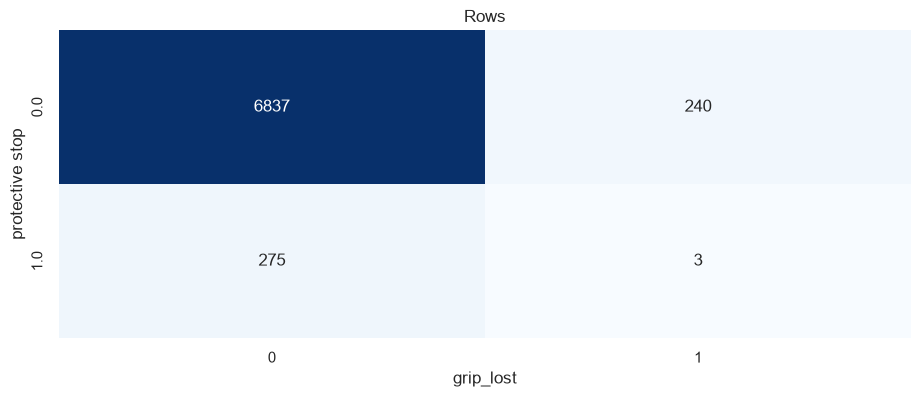

Cycles:
 gl     0   1
ps          
0.0  134  30
1.0   64  21
Fisher exact test p-value: 0.249


In [13]:
tab = pd.crosstab(d["PS"], d["GL"])
sns.heatmap(tab, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("grip_lost"); plt.ylabel("protective stop"); plt.title("Rows")
plt.show()

cyc = df.groupby("cycle_id").agg(gl=("GL", "max"), ps=("PS", "max"))
ct = pd.crosstab(cyc["ps"], cyc["gl"])
print("Cycles:\n", ct)
print("Fisher exact test p-value:", round(stats.fisher_exact(ct)[1], 3))

**Reading:** the two faults almost never happen at the same second and their co-occurrence per cycle is not significant: `Robot_ProtectiveStop` is excluded from the inputs.

## 9. Missing rows and their effect on events

54 empty rows, in 53 cycles
events before dropping: 77, after dropping: 74


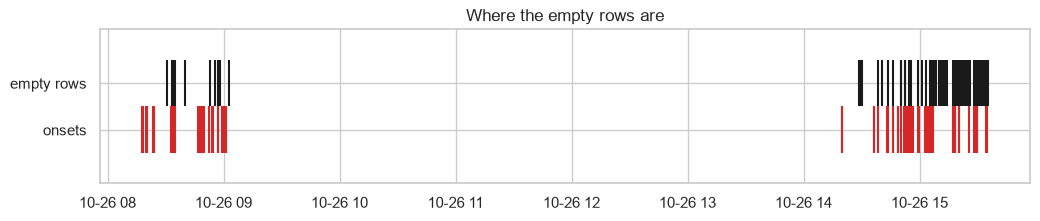

In [14]:
miss = df.index[df["nan_row"]]
print(f"{len(miss)} empty rows, in {df.loc[miss, 'cycle_id'].nunique()} cycles")
events_before = df["onset"].sum()
g = df.loc[~df["nan_row"], "GL"].reset_index(drop=True)
events_after = ((g == 1) & (g.shift(fill_value=0) == 0)).sum()
print(f"events before dropping: {events_before}, after dropping: {events_after}")

plt.figure(figsize=(12, 2))
plt.eventplot([df.loc[miss, "ts"]], colors="k", lineoffsets=1)
plt.eventplot([df.loc[df["onset"], "ts"]], colors="tab:red", lineoffsets=0)
plt.yticks([0, 1], ["onsets", "empty rows"]); plt.title("Where the empty rows are")
plt.show()

**Reading:** dropping the empty rows glues neighbouring events together (77 → 74). Empty rows should be treated as **breaks** in the series (no window across them, never predicted) rather than silently removed.

## Summary of the relations
1. **Time / temperature confounding**: grip losses are much more frequent during the cold start; temperatures look predictive mainly because of that.
2. **Temperatures are redundant** (r ≈ 1): keep one.
3. **During** a loss, speeds and loads change strongly → consequences, leakage risk → predict before the onset.
4. **Cycle position** is a strong predictor (onsets at 14–23 s) → mandatory baseline.
5. **Precursors exist but are short**: currents J1/J2 deviate 1–6 s before the onset (relative to the normal cycle) → horizon of a few seconds, features relative to the cycle position.
6. `Tool_current` alone does not separate the classes; `Robot_ProtectiveStop` is unrelated to grip losses.
7. Events can be very close (6 pairs ≤ 10 s apart) and several per cycle → evaluate per event, split per cycle.